In [226]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy

import matplotlib.cm as cm

from matplotlib import rc
rc('font',**{'family':'serif','serif':['Times New Roman']})
rc('text', usetex=True)

In [227]:
def create_circular_mask(img_ref, center_row, center_col, radius):
    #The radius will correspond to the larger period
    mask_circ = np.zeros_like(img_ref)
    for ii in range(center_col-radius, center_col + radius + 1):
        for jj in range(center_row-radius, center_row + radius + 1):
            d = np.sqrt((center_col-ii)**2 + (center_row-jj)**2)    
            if (d < radius):
                mask_circ[ii][jj] = 1

    return mask_circ

In [228]:
img = plt.imread('./images/RefExp.tif')

In [229]:
img.shape

(480, 480)

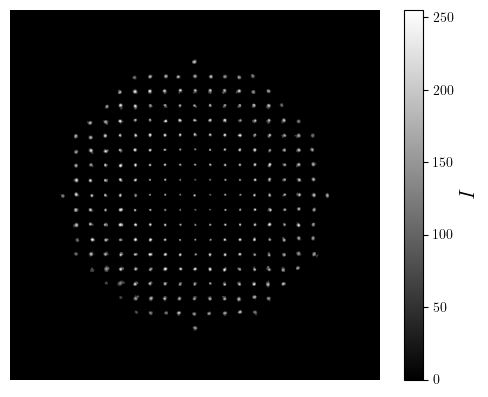

In [230]:
plt.imshow(img, cmap="gray")
plt.axis('off')
plt.colorbar().set_label("${I}$", fontsize = 16)

We proceed to normalize the image

In [231]:
img = img / np.max(img)

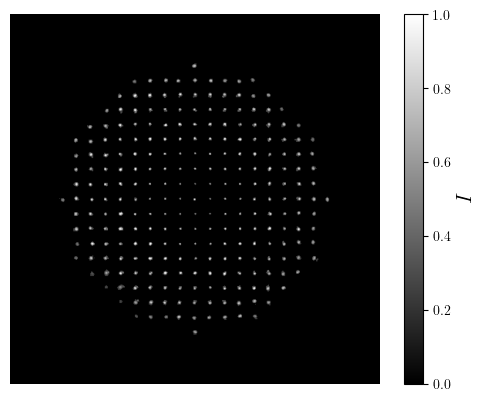

In [232]:
plt.imshow(img, cmap="gray")
plt.axis('off')
plt.colorbar().set_label("${I}$", fontsize = 16)

In [233]:
fft_img = np.fft.fft2(img)
fft_result = np.fft.fftshift(fft_img)

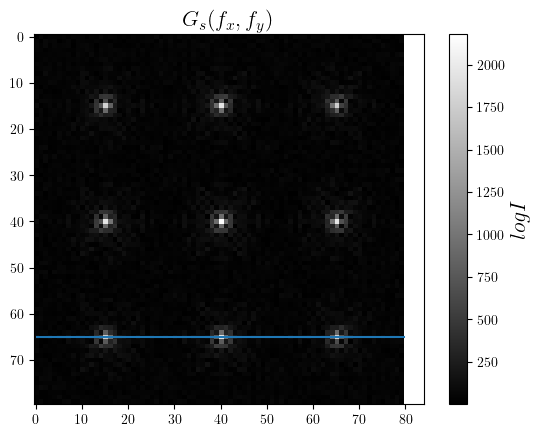

In [234]:
plt.imshow((np.abs(fft_result))[200:280, 200:280], cmap="gray")
plt.title(f'$G_s(f_x,f_y)$', fontsize=16)
plt.colorbar().set_label("$log{I}$", fontsize = 16)
plt.hlines(y= 65, xmin = 0, xmax = 80)

It has a spatial period of 25 pixels. For that reason, I am going to begin at 240, move 25 pixels to the right and then make a circular mask of 12.5 pixels radius

In [235]:
period = 25 

center = 240

radius = int(25.0/2)

mask_x_ref = create_circular_mask(fft_result, 240+period, 240, radius)


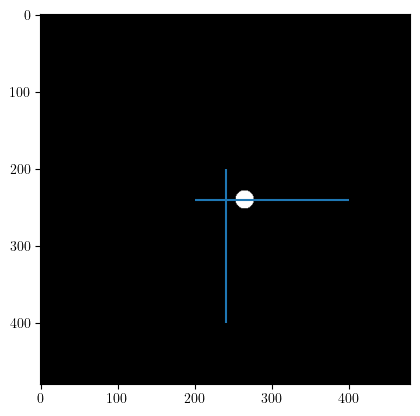

In [236]:
plt.imshow(np.abs(mask_x_ref), cmap="gray")
plt.vlines(x=240, ymin=200, ymax=400)
plt.hlines(y=240, xmin=200, xmax=400)

In [237]:
img_fft_filtered_x_ref = fft_result * mask_x_ref

C:\Users\PC\AppData\Local\Temp\ipykernel_2956\3819150650.py:1: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(np.abs(img_fft_filtered_x_ref)), cmap="gray")


Text(0.5, 1.0, '$G(f_x, f_y)$')

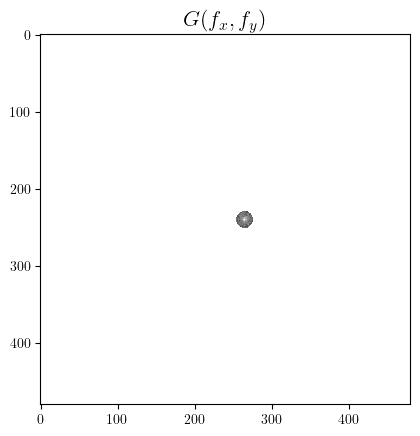

In [238]:
plt.imshow(np.log(np.abs(img_fft_filtered_x_ref)), cmap="gray")
plt.title("$G(f_x, f_y)$", fontsize = 16)
# plt.axis('off')

In [239]:
img_recovered_x_ref = np.fft.ifftshift(np.fft.ifft2(img_fft_filtered_x_ref))

(-0.5, 479.5, 479.5, -0.5)

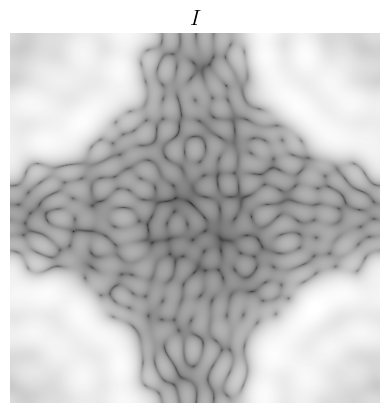

Now we proceed to isolate one of the spots in the vertical direction

In [241]:
mask_y_ref = create_circular_mask(fft_result, 240, 240+period, radius)

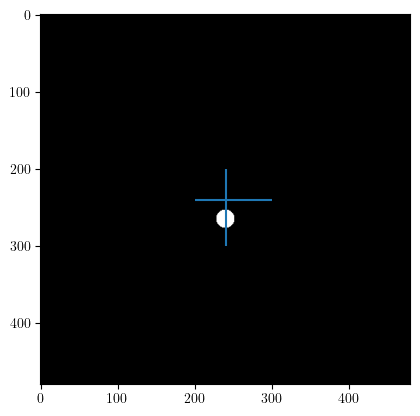

In [242]:
plt.imshow(np.abs(mask_y_ref), cmap="gray")
plt.vlines(x=240, ymin=200, ymax = 300)
plt.hlines(y=240, xmin=200, xmax=300)

In [243]:
fft_filtered_y_ref = fft_result * mask_y_ref

C:\Users\PC\AppData\Local\Temp\ipykernel_2956\2107970280.py:1: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(np.abs(fft_filtered_y_ref)), cmap="gray")


Text(0.5, 1.0, '$G(f_x, f_y)$')

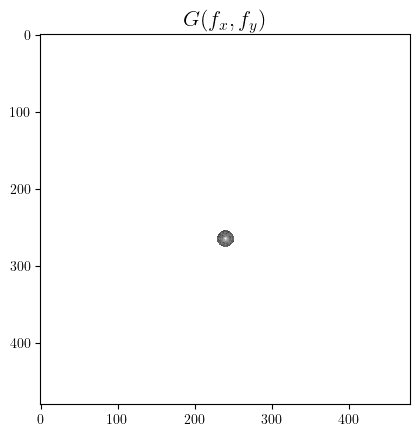

In [244]:
plt.imshow(np.log(np.abs(fft_filtered_y_ref)), cmap="gray")
plt.title("$G(f_x, f_y)$", fontsize = 16)

In [245]:
img_recovered_y_ref = np.fft.ifftshift(np.fft.ifft2(fft_filtered_y_ref))

Text(0.5, 1.0, '$I$')

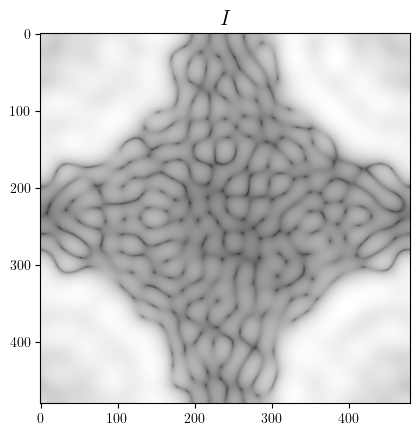

In [246]:
plt.imshow(np.log(np.abs(img_recovered_y_ref)), cmap="gray")
plt.title("$I$", fontsize = 16)
# plt.axis('off')

<center> <h1> <b> Imagen a probar </b></h1> </center>

In [247]:
img_test = plt.imread('./images/ConicaExp.tif')

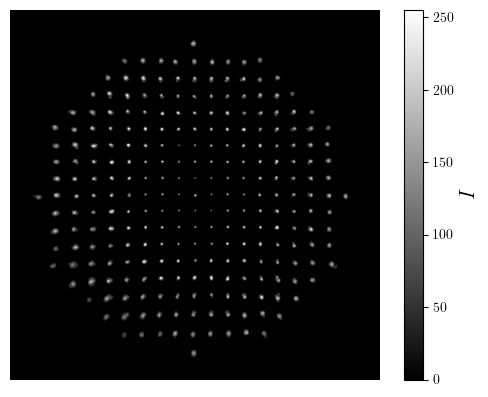

In [248]:
plt.imshow(img_test, cmap="gray")
plt.axis('off')
plt.colorbar().set_label("${I}$", fontsize = 16)

In [249]:
img_test = img_test / np.max(img_test)

In [250]:
fft_img_test = np.fft.fft2(img_test)
fft_result_test = np.fft.fftshift(fft_img_test)

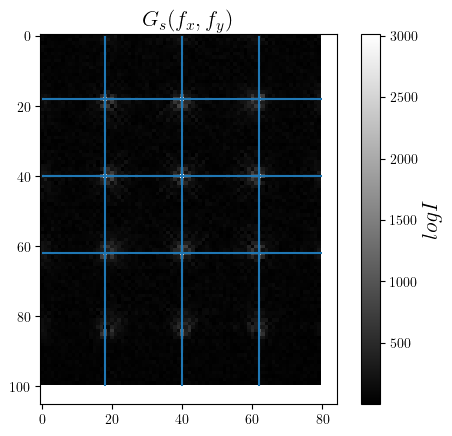

In [251]:
plt.imshow((np.abs(fft_result_test)[200:300, 200:280]), cmap="gray")
plt.title(f'$G_s(f_x,f_y)$', fontsize=16)
plt.colorbar().set_label("$log{I}$", fontsize = 16)
plt.vlines(x=40, ymin=0, ymax = 100)
plt.vlines(x=18, ymin=0, ymax = 100)
plt.vlines(x=62, ymin=0, ymax = 100)

plt.hlines(y=18, xmin =0, xmax=80)
plt.hlines(y=40, xmin =0, xmax=80)
plt.hlines(y=62, xmin =0, xmax=80)

# plt.hlines(y= 65, xmin = 0, xmax = 80)

Based on the information before, it is known that the x and y spatial period is 22 pixels (not 25 as before)

In [252]:
period_test = 22
radius_test = int(22/2)

center = 240

mask_x_test = create_circular_mask(fft_result, 240+period_test, 240, radius_test)

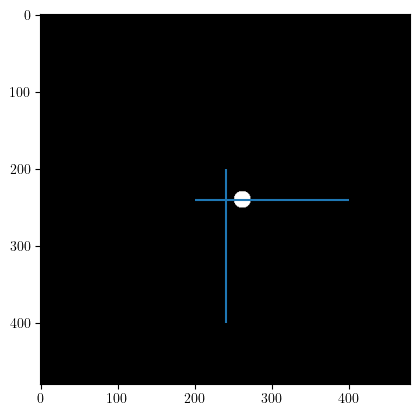

In [253]:
plt.imshow(np.abs(mask_x_test), cmap="gray")
plt.vlines(x=240, ymin=200, ymax=400)
plt.hlines(y=240, xmin=200, xmax=400)

In [254]:
img_fft_filtered_x_test = fft_result * mask_x_test

C:\Users\PC\AppData\Local\Temp\ipykernel_2956\2215433703.py:1: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(np.abs(img_fft_filtered_x_ref)), cmap="gray")


Text(0.5, 1.0, '$H(f_x, f_y)$')

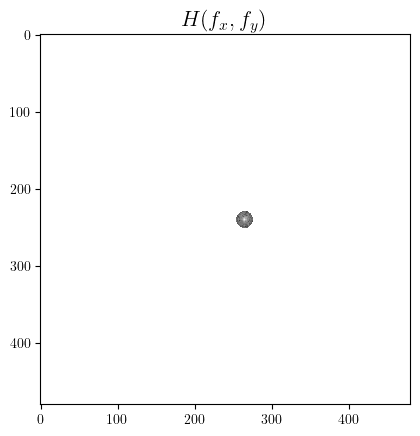

In [255]:
plt.imshow(np.log(np.abs(img_fft_filtered_x_ref)), cmap="gray")
plt.title("$H(f_x, f_y)$", fontsize = 16)
# plt.axis('off')

In [256]:
img_recovered_x_test = np.fft.ifftshift(np.fft.ifft2(img_fft_filtered_x_test))

(-0.5, 479.5, 479.5, -0.5)

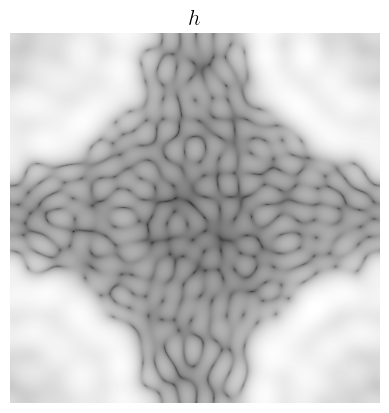

In [257]:
plt.imshow(np.log(np.abs(img_recovered_x_ref)), cmap="gray")
plt.title("$h$", fontsize = 16)
plt.axis('off')

Now, we are going to study the vertical direction

In [258]:
mask_y_test = create_circular_mask(fft_result, 240, 240+period_test, radius_test)

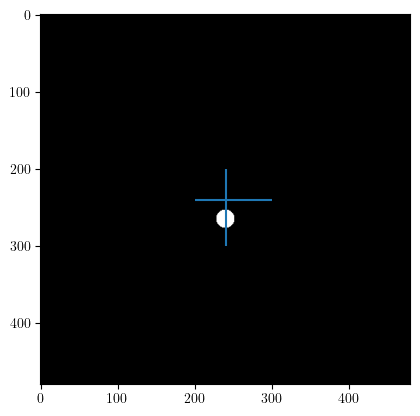

In [259]:
plt.imshow(np.abs(mask_y_ref), cmap="gray")
plt.vlines(x=240, ymin=200, ymax = 300)
plt.hlines(y=240, xmin=200, xmax=300)

In [260]:
fft_filtered_y_test = fft_result * mask_y_test

C:\Users\PC\AppData\Local\Temp\ipykernel_2956\1359559708.py:1: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(np.abs(fft_filtered_y_ref)), cmap="gray")


Text(0.5, 1.0, '$H_y(f_x, f_y)$')

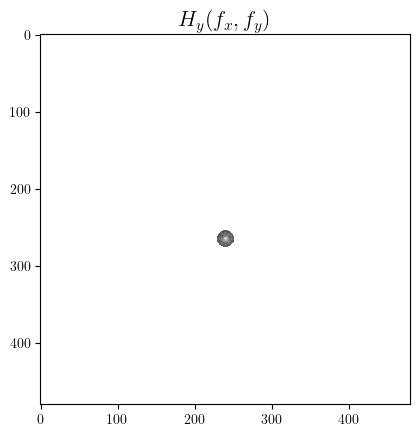

In [261]:
plt.imshow(np.log(np.abs(fft_filtered_y_ref)), cmap="gray")
plt.title("$H_y(f_x, f_y)$", fontsize = 16)

In [262]:
img_recovered_y_test = np.fft.ifftshift(np.fft.ifft2(fft_filtered_y_test))

Text(0.5, 1.0, '$I$')

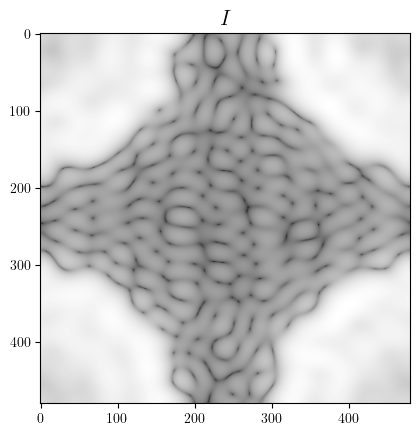

In [263]:
plt.imshow(np.log(np.abs(img_recovered_y_test)), cmap="gray")
plt.title("$I$", fontsize = 16)
# plt.axis('off')

I have already extracted the info I need. Let see what proceeds

First, we are going to do the quotient between the phases oof the aberrated and the reference image for the x positions and the y positions

In [267]:
hx_gx = img_recovered_x_test/img_recovered_x_ref
hy_gy = img_recovered_y_test/img_recovered_y_ref

In [270]:
phi_x = np.arctan2(hx_gx.imag, hx_gx.real)
gamma_y = np.arctan2(hy_gy.imag, hy_gy.real)

In [271]:
import numpy as np

# --- 1. USER INPUT REQUIRED ---
# You MUST set this value based on your image acquisition system.
# Example: If your spot pitch is 10 pixels, f_grid = 1/10 = 0.1
f_grid = 1/25 # <--- REPLACE WITH YOUR ACTUAL SPATIAL FREQUENCY (in cycles/pixel)
# ------------------------------

# 2. Compute the final slope maps
# (The slopes are now in units of [length]/[pixel_length])
slope_map_x = phi_x / (2 * np.pi * f_grid)
slope_map_y = gamma_y / (2 * np.pi * f_grid)

# You now have the two components of the wavefront gradient!

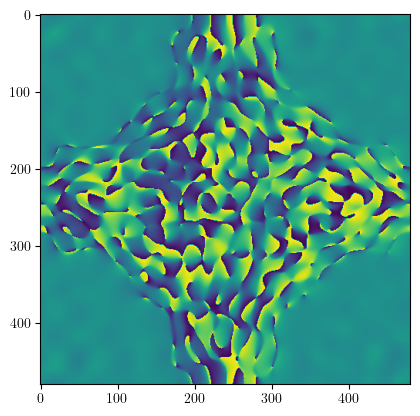

In [272]:
plt.imshow(slope_map_x)

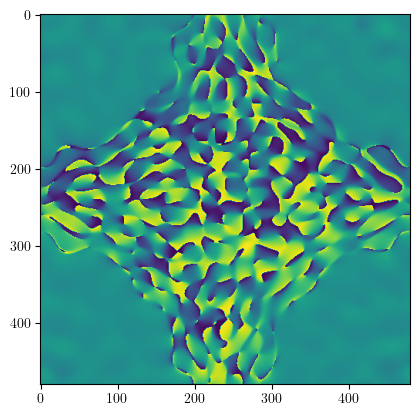

In [273]:
plt.imshow(slope_map_y)